In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95"

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

In [3]:
from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.sdf_primitives import sphere_sdf, bbox_sdf
from sphereWalker.integrator import WoSIntegrator, DifferentialWoSIntegrator
from sphereWalker.sampling import sample_uniform_1sphere
from utils.losses import volume_integral_loss_grad, surface_integral_loss_grad, l2_loss, dL2_du

In [4]:
def const_source_fn(x):
    return 4.0

def zero_boundary_condition(point: jnp.ndarray) -> jnp.ndarray:
    return 0.0

In [5]:
reference_theta = jnp.array([1.0])
bbox_min = jnp.array([-1.5, -1.5])
bbox_max = jnp.array([1.5, 1.5])
key = jax.random.PRNGKey(0)
N = 100000

reference_theta = {'center': jnp.array([0.0, 0.0]), 'radius': jnp.array(1.0)}
target_sdf = sdfImplicit(fn=sphere_sdf, dim=2)

reference_solve = WoSIntegrator(
    empty_sphere_fn=target_sdf.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,
    print_progress=True
)

test_points, test_mask = target_sdf.sample_points_inside(reference_theta, key, bbox_min, bbox_max, N)
reference_estimate = reference_solve.integrate_batch(reference_theta,test_points[test_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)

Remaining Active States: 1000000 | Next Task Index: 1000000/51200000
Process called so far. 1
Remaining Active States: 1000000 | Next Task Index: 1999606/51200000
Process called so far. 2
Remaining Active States: 1000000 | Next Task Index: 2999194/51200000
Process called so far. 3
Remaining Active States: 1000000 | Next Task Index: 3998732/51200000
Process called so far. 4
Remaining Active States: 1000000 | Next Task Index: 4998271/51200000
Process called so far. 5
Remaining Active States: 1000000 | Next Task Index: 5997848/51200000
Process called so far. 6
Remaining Active States: 1000000 | Next Task Index: 6997404/51200000
Process called so far. 7
Remaining Active States: 1000000 | Next Task Index: 7996998/51200000
Process called so far. 8
Remaining Active States: 1000000 | Next Task Index: 8996568/51200000
Process called so far. 9
Remaining Active States: 1000000 | Next Task Index: 9996158/51200000
Process called so far. 10
Remaining Active States: 1000000 | Next Task Index: 1099570

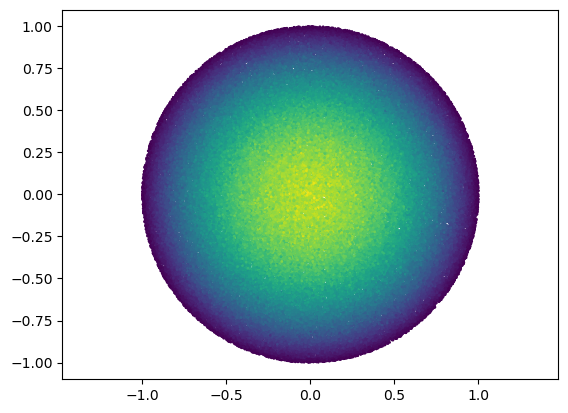

In [6]:
plt.scatter(test_points[test_mask,0], test_points[test_mask,1], s=1, c=reference_estimate.w[:, 0])
plt.axis('equal')
plt.show()

In [7]:
theta = jnp.array(0.1)  # Parameter for the sphere radius
parameters = {'center': jnp.array([0.0, 0.0]), 'radius': theta}
key = jax.random.PRNGKey(1)
N = 100000
sdf_to_opt = sdfImplicit(fn=lambda r, x: sphere_sdf({'center': jnp.array([0.0, 0.0]), 'radius': r}, x), dim=2)

dif_integrator = DifferentialWoSIntegrator(
    empty_sphere_fn=sdf_to_opt.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    Df=sdf_to_opt.dirichlet_boundary_differential,
    V_n=sdf_to_opt.normal_surface_velocity,
    normal_fn=sdf_to_opt.normal_at,
    offset_l=0.01,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,
    print_progress=True
)

primary_integrator = WoSIntegrator(
    empty_sphere_fn=sdf_to_opt.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,

)

test_points, test_mask = sdf_to_opt.sample_points_inside(theta, key, bbox_min, bbox_max, N)

In [8]:
deriv_field_estimate = dif_integrator.integrate_batch(theta, test_points[test_mask], rng_key=jax.random.PRNGKey(0), init_trust_region_size=jnp.inf, n_samples=512)

Remaining Active States: 1000000 | Next Task Index: 1000000/49623552
Process called so far. 1
Remaining Active States: 1000000 | Next Task Index: 1000000/49623552
Process called so far. 2
Remaining Active States: 1000000 | Next Task Index: 1999972/49623552
Process called so far. 3
Remaining Active States: 1000000 | Next Task Index: 2000000/49623552
Process called so far. 4
Remaining Active States: 1000000 | Next Task Index: 2999929/49623552
Process called so far. 5
Remaining Active States: 1000000 | Next Task Index: 3000000/49623552
Process called so far. 6
Remaining Active States: 1000000 | Next Task Index: 3999893/49623552
Process called so far. 7
Remaining Active States: 1000000 | Next Task Index: 4000000/49623552
Process called so far. 8
Remaining Active States: 1000000 | Next Task Index: 4999852/49623552
Process called so far. 9
Remaining Active States: 1000000 | Next Task Index: 5000000/49623552
Process called so far. 10
Remaining Active States: 1000000 | Next Task Index: 5999820

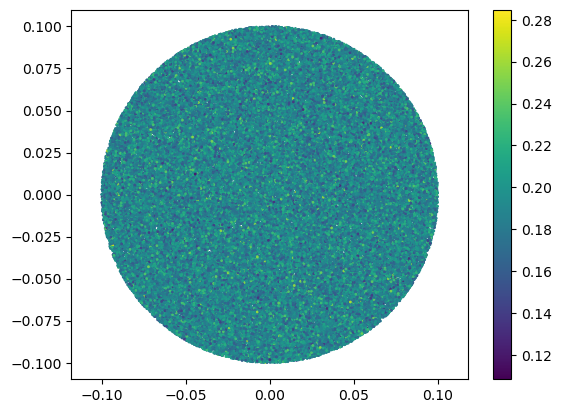

In [9]:
plt.scatter(test_points[test_mask, 0], test_points[test_mask, 1], c=deriv_field_estimate.w.squeeze(), s=1)
plt.axis('equal')
plt.colorbar()
plt.show()

In [10]:
def point_grid(bbox_min, bbox_max, num_points_per_axis):
    axes = [jnp.linspace(bbox_min[i], bbox_max[i], num_points_per_axis) for i in range(len(bbox_min))]
    mesh = jnp.meshgrid(*axes, indexing='ij')
    grid_points = jnp.stack([m.flatten() for m in mesh], axis=-1)
    return grid_points

def classify_grid(sdf_fn, params, grid_points, level_set=0.0):
    sdf_values = jax.vmap(sdf_fn, in_axes=(None, 0))(params, grid_points)
    inside_mask = sdf_values < level_set
    outside_mask = sdf_values > level_set
    on_surface_mask = jnp.isclose(sdf_values, level_set, atol=1e-3)
    return inside_mask, outside_mask, on_surface_mask

In [11]:
def sgd_step(params, opt_state, grads, optimizer):
    updates, new_opt_state = optimizer.update(grads, opt_state)
    params_new = optax.apply_updates(params, updates)
    return params_new, new_opt_state

In [12]:
reference_theta = jnp.array(1.0)
theta = jnp.array(0.1)  # Parameter for the sphere radius
bbox_min = jnp.array([-1.5, -1.5])
bbox_max = jnp.array([1.5, 1.5])
key = jax.random.PRNGKey(0)
N = 10000

#reference_fn = lambda t, p: jnp.maximum(-sphere_sdf(radius=t, point=p), bbox_sdf(bbox_min, bbox_max, p))
func_of_interest = lambda r, x: sphere_sdf({'center': jnp.array([0.0, 0.0]), 'radius': r}, x)
implicit_surface = sdfImplicit(fn=func_of_interest, dim=2)


optimizer_loop_points = point_grid(bbox_min, bbox_max, 2000)
inside_mask, outside_mask, on_surface_mask = classify_grid(implicit_surface, reference_theta, optimizer_loop_points, level_set=0.0)

reference_solver = WoSIntegrator(
    empty_sphere_fn=implicit_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

inside_reference_mask = jax.vmap(implicit_surface, in_axes=(None, 0))(reference_theta, optimizer_loop_points) < 0.0
reference_estimate = reference_solver.integrate_batch(reference_theta, optimizer_loop_points[inside_reference_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
reference_estimate_full = jnp.zeros((optimizer_loop_points.shape[0], 1))
reference_estimate_full = reference_estimate_full.at[inside_reference_mask].set(reference_estimate.w)

theta_solver = WoSIntegrator(
    empty_sphere_fn=implicit_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

dif_integrator = DifferentialWoSIntegrator(
    empty_sphere_fn=implicit_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    Df=implicit_surface.dirichlet_boundary_differential,
    V_n=implicit_surface.normal_surface_velocity,
    normal_fn=implicit_surface.normal_at,
    offset_l=0.01,
    dim=implicit_surface.dim,
    level_set=implicit_surface.level_set,
    eps=1e-3,
    max_steps=1000
)

NSTEPS = 10
learning_rate = 1.0

params_to_opt = jnp.copy(theta)
optimizer = optax.sgd(learning_rate)
opt_state = optimizer.init(params_to_opt)

vol_grads_wos = {}
sur_grads_wos = {}

theta_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]

In [13]:
to_solve_at_mask.sum() / inside_mask.sum()

NameError: name 'to_solve_at_mask' is not defined

In [33]:
(jnp.pi * params_to_opt.squeeze()**2) #/ to_solve_at_mask.sum()

Array(1647.4073, dtype=float32)

In [32]:
(bbox_max - bbox_min).prod() * inside_mask.mean()

Array(3.1383991, dtype=float32)

In [18]:
for theta in theta_values:
    for samples in [1, 10, 100]:
        params_to_opt = jnp.ones_like(reference_theta) * theta
        if float(params_to_opt.squeeze()) > float(reference_theta.squeeze()):
            inside_mask, outside_mask, on_surface_mask = classify_grid(implicit_surface, reference_theta, optimizer_loop_points, level_set=0.0)
        else:
            inside_mask, outside_mask, on_surface_mask = classify_grid(implicit_surface, params_to_opt, optimizer_loop_points, level_set=0.0)
        print(f"Inside points: {inside_mask.sum()}")
        to_solve_at_mask = jnp.logical_and(inside_mask, inside_reference_mask)
        reference_estimate = reference_estimate_full[to_solve_at_mask]
        deriv_field_estimate = dif_integrator.integrate_batch(params_to_opt, optimizer_loop_points[to_solve_at_mask], rng_key=jax.random.PRNGKey(1), init_trust_region_size=jnp.inf, n_samples=samples).w
        primary_field_estimate = theta_solver.integrate_batch(params_to_opt, optimizer_loop_points[to_solve_at_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=samples).w
        volume = (bbox_max - bbox_min).prod() * to_solve_at_mask.mean()
        volume_loss_grad = volume_integral_loss_grad(dL2_du, volume=volume, solution_u=primary_field_estimate, solution_target=reference_estimate, del_solution_del_theta=deriv_field_estimate)
          # Scale the loss gradient by the ratio of total inside points to the points we solve at, to account for different number of points when theta > or < reference_theta
        vol_grads_wos[(theta, samples)] = volume_loss_grad
        if float(params_to_opt.squeeze()) < float(reference_theta.squeeze()):
            surface_grads_mask = jnp.logical_and(inside_reference_mask, on_surface_mask)
            reference_field_at_surface = reference_estimate_full[surface_grads_mask]

            surface_volume_approx = (bbox_max - bbox_min).prod() * surface_grads_mask.mean()
            surface_loss = surface_integral_loss_grad(
                loss_fn=l2_loss, epsilon=1e-3, volume=surface_volume_approx,
                solution_u=jax.vmap(theta_solver.boundary_condition_fn)(optimizer_loop_points[surface_grads_mask]),
                solution_target=reference_field_at_surface.squeeze(), 
                normal_velocity_field=jax.vmap(implicit_surface.normal_surface_velocity, in_axes=(None, 0))(params_to_opt, optimizer_loop_points[surface_grads_mask]))
            sur_grads_wos[(theta, samples)] = surface_loss
            volume_loss_grad += surface_loss
        params_to_opt, opt_state = sgd_step(params_to_opt, opt_state, volume_loss_grad, optimizer)
        print(f"samples {samples}, theta: {theta}, theta updated: {params_to_opt}, volume loss grad: {volume_loss_grad}, surface loss grad: {surface_loss if 'surface_loss' in locals() else 'N/A'}")
        break

Inside points: 13956
samples 1, theta: 0.1, theta updated: [-0.18529692], volume loss grad: [0.28529692], surface loss grad: 0.29111048579216003
Inside points: 55784
samples 1, theta: 0.2, theta updated: [-0.3285945], volume loss grad: [0.5285945], surface loss grad: 0.5758901834487915
Inside points: 125572
samples 1, theta: 0.3, theta updated: [-0.34850985], volume loss grad: [0.64850986], surface loss grad: 0.7998738288879395
Inside points: 223144
samples 1, theta: 0.4, theta updated: [-0.1486769], volume loss grad: [0.5486769], surface loss grad: 0.8780161142349243
Inside points: 348728
samples 1, theta: 0.5, theta updated: [0.18577492], volume loss grad: [0.31422508], surface loss grad: 0.9005574584007263
Inside points: 502180
samples 1, theta: 0.6, theta updated: [0.70550936], volume loss grad: [-0.10550934], surface loss grad: 0.7567973732948303
Inside points: 683440
samples 1, theta: 0.7, theta updated: [1.2234082], volume loss grad: [-0.52340823], surface loss grad: 0.575265944

In [15]:
def analytical_boundary_integral_gradient(R, R_reference, c):
    return jnp.pi * c**2 * R**3 * (R**2 - R_reference**2) * (1/8)

def analytical_surface_integral_gradient(R, R_reference, c):
    return jnp.pi * R * c**2 * (R_reference**2 - R**2)**2 * (1/16)

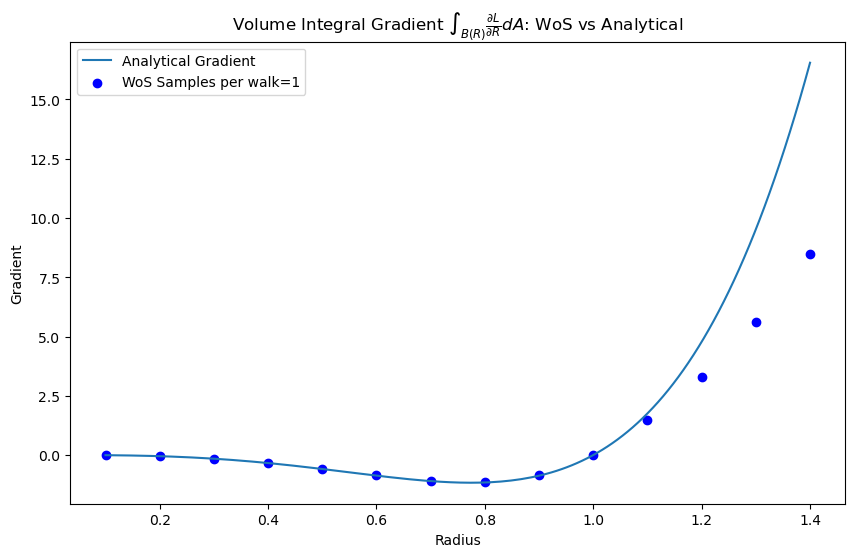

In [16]:
thetas = jnp.linspace(0.1, 1.4, 140)
analytical_boundary_grad = jax.vmap(analytical_boundary_integral_gradient, in_axes=(0, None, None))(thetas, reference_theta, 4.0)

fig = plt.figure(figsize=(10, 6))

plt.plot(thetas, analytical_boundary_grad, label='Analytical Gradient')

for (theta, samples), vol_grad in vol_grads_wos.items():
    if samples == 100:
        color = 'red'
    elif samples == 10:
        color = 'green'
    else:
        color = 'blue'
    plt.scatter(theta, vol_grad, label=f'WoS Samples per walk={samples}' if theta == 0.1 else None, c=color)

plt.legend()
plt.title(r'Volume Integral Gradient $\int_{B(R)} \frac{\partial L}{\partial R} dA$: WoS vs Analytical')
plt.xlabel('Radius')
plt.ylabel('Gradient')

plt.show()

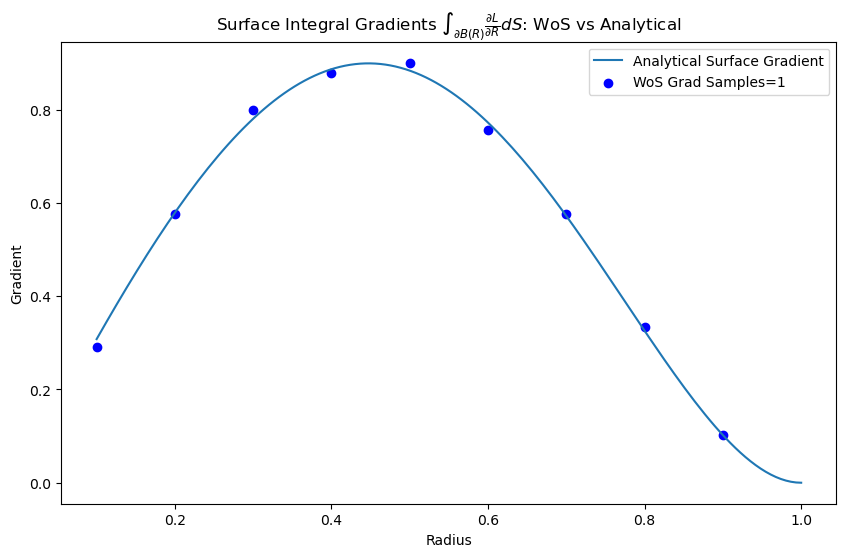

In [19]:
thetas = jnp.linspace(0.1, 1.0, 140)
analytical_surface_grad = jax.vmap(analytical_surface_integral_gradient, in_axes=(0, None, None))(thetas, reference_theta, 4.0)

fig = plt.figure(figsize=(10, 6))
plt.plot(thetas, analytical_surface_grad, label='Analytical Surface Gradient')

for (theta, samples), sur_grad in sur_grads_wos.items():
    if samples == 100:
        color = 'red'
    elif samples == 10:
        color = 'green'
    else:
        color = 'blue'
    plt.scatter(theta, sur_grad, label=f'WoS Grad Samples={samples}' if theta == 0.1 else None, c=color)

plt.xlabel('Radius')
plt.ylabel('Gradient')
plt.title(r'Surface Integral Gradients $\int_{\partial B(R)} \frac{\partial L}{\partial R} dS$: WoS vs Analytical')
plt.legend()
plt.show()

## Debug with analytical solution

In [64]:
def analytical_solution(c, radius, point):
    """
    Analytical solution for the Poisson equation with a constant source term and zero Dirichlet boundary conditions on a circle of given radius.
    The solution is given by: u(r) = (R^2 - r^2) / 4
    where R is the radius of the circle and r is the distance from the center.
    """
    r = jnp.linalg.norm(point)
    return (radius**2 - r**2) * c / 4.0

def analytical_solution_gradient(c, radius, point):
    """
    Gradient of the analytical solution with respect to the radius parameter.
    du/dR = R / 2
    """
    return radius * c / 2.0

def del_L_del_radius_analytical(c, target_radius, to_opt_radius, point):
    """
    Analytical gradient of the loss with respect to the radius parameter.
    Using the analytical solution and its gradient.
    L = 0.5 * (u_estimate - u_target)^2
    dL/dR = (u_estimate - u_target) * du_estimate/dR
    where du_estimate/dR is given by analytical_solution_gradient
    """
    u_target = analytical_solution(c, target_radius, point)
    u_estimate = analytical_solution(c, to_opt_radius, point)
    du_dR = analytical_solution_gradient(c, to_opt_radius, point)
    return (u_estimate - u_target) * du_dR

def velocity_normal(radius, point):
    """
    Normal velocity of the boundary with respect to the radius parameter.
    For a circle, the normal velocity is simply 1 (expanding outward).
    """
    return 1.0

In [65]:
R = jnp.array(1.0)
R_reference = 0.8
c = 4.0

analytical_boundary_integral_gradient(R, R_reference, c)

Array(2.261947, dtype=float32, weak_type=True)

In [66]:
del_L_del_radius_analytical(c, R_reference, R, jnp.array([0.5, 0.5])) * jnp.pi * R**2

Array(2.2619467, dtype=float32)

In [67]:
R = jnp.array(0.1)
R_reference = jnp.array(1.0)
key = jax.random.PRNGKey(0)
bbox_min = jnp.array([-1.5, -1.5])
bbox_max = jnp.array([1.5, 1.5])

sdf_fn = lambda r, x: sphere_sdf({'radius': r, 'center': jnp.array([0.0, 0.0])}, x)
sdf_surface = sdfImplicit(fn=sdf_fn, params=R, dim=2)
if R > R_reference:
    test_points, test_mask = sdf_surface.sample_points_inside(R_reference, key, bbox_min, bbox_max, num_points=10000)
else:
    test_points, test_mask = sdf_surface.sample_points_inside(R, key, bbox_min, bbox_max, num_points=10000)
analytical_values = jax.vmap(lambda p: analytical_solution(c, R.squeeze(), p))(test_points[test_mask])
analytical_gradients = jax.vmap(lambda p: analytical_solution_gradient(c, R.squeeze(), p))(test_points[test_mask])

In [68]:
solver = WoSIntegrator(
    empty_sphere_fn=sdf_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=lambda x: c,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,
)

dif_solver = DifferentialWoSIntegrator(
    empty_sphere_fn=sdf_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=lambda x: c,
    Df=sdf_surface.dirichlet_boundary_differential,
    V_n=sdf_surface.normal_surface_velocity,
    normal_fn=sdf_surface.normal_at,
    offset_l=0.01,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

numerical_estimate = solver.integrate_batch(R, test_points[test_mask], rng_key=jax.random.PRNGKey(0), init_trust_region_size=jnp.inf, n_samples=200)
numerical_gradient_estimate = dif_solver.integrate_batch(R, test_points[test_mask], rng_key=jax.random.PRNGKey(0), init_trust_region_size=jnp.inf, n_samples=1000)

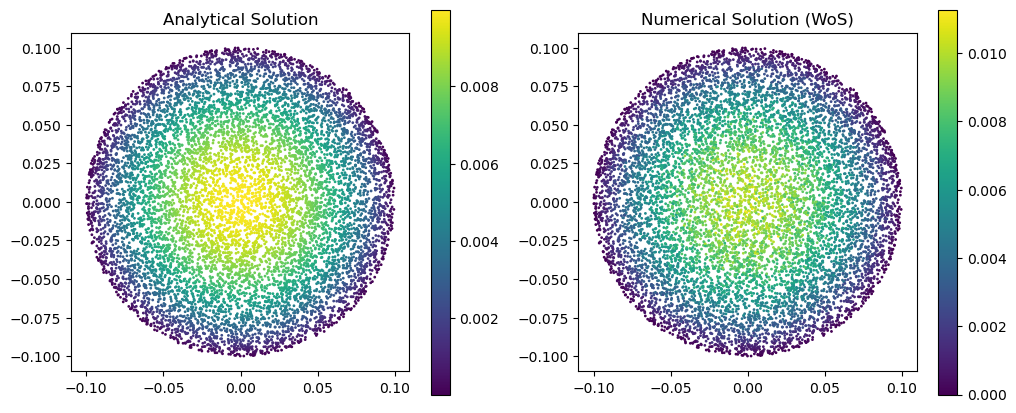

In [69]:
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1)
sc1 = ax1.scatter(test_points[test_mask,0], test_points[test_mask,1], c=analytical_values, s=1, cmap='viridis')
plt.colorbar(sc1, ax=ax1)
ax1.set_title('Analytical Solution')
ax1.set_aspect('equal')

ax2 = fig.add_subplot(1, 2, 2)
sc2 = ax2.scatter(test_points[test_mask,0], test_points[test_mask,1], c=numerical_estimate.w.squeeze(), s=1, cmap='viridis')
plt.colorbar(sc2, ax=ax2)
ax2.set_title('Numerical Solution (WoS)')
ax2.set_aspect('equal')
plt.show()

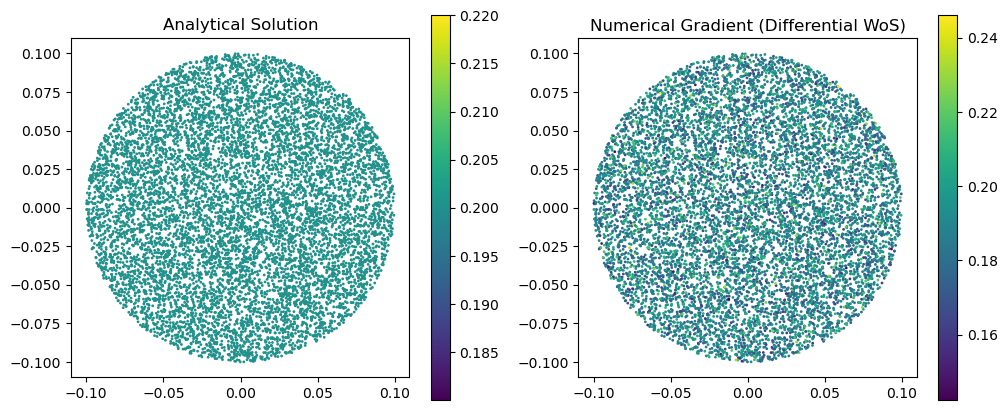

In [70]:
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(1, 2, 1)
sc1 = ax1.scatter(test_points[test_mask,0], test_points[test_mask,1], c=analytical_gradients.squeeze(), s=1, cmap='viridis')
plt.colorbar(sc1, ax=ax1)
ax1.set_title('Analytical Solution')
ax1.set_aspect('equal')

ax2 = fig.add_subplot(1, 2, 2)
sc2 = ax2.scatter(test_points[test_mask,0], test_points[test_mask,1], c=numerical_gradient_estimate.w.squeeze(), s=1, cmap='viridis')
plt.colorbar(sc2, ax=ax2)
ax2.set_title('Numerical Gradient (Differential WoS)')
ax2.set_aspect('equal')
plt.show()

In [71]:
volume_integral_loss_grad(target=jax.vmap(analytical_solution, in_axes=(None, None, 0))(c, R_reference.squeeze(), test_points[test_mask]),
                          estimate=numerical_estimate.w.squeeze(),
                          estimate_del_theta=numerical_gradient_estimate.w.squeeze(),
                          dx=1) * (jnp.pi * R.squeeze()**2) / test_mask.sum()

Array(-0.0058819, dtype=float32)

In [72]:
volume_integral_loss_grad(target=jax.vmap(analytical_solution, in_axes=(None, None, 0))(c, R_reference.squeeze(), test_points[test_mask]),
                          estimate=jax.vmap(analytical_solution, in_axes=(None, None, 0))(c, R.squeeze(), test_points[test_mask]),
                          estimate_del_theta=jax.vmap(analytical_solution_gradient, in_axes=(None, None, 0))(c, R.squeeze(), test_points[test_mask]),
                          dx=1) * (jnp.pi * R.squeeze()**2) / test_mask.sum()

Array(-0.00622035, dtype=float32)

In [77]:
surface_points = jax.vmap(lambda key: sample_uniform_1sphere(key, jnp.float32))(jax.random.split(jax.random.PRNGKey(0), 1000)) * (R.squeeze())
ref_solution_at_surface = jax.vmap(analytical_solution, in_axes=(None, None, 0))(c, R_reference.squeeze(), surface_points)
surface_velocity = jax.vmap(velocity_normal, in_axes=(None, 0))(R, surface_points)

surface_grad = 2 * jnp.pi * R.squeeze() * boundary_integral_loss_grad(
    target=ref_solution_at_surface,
    estimate=jax.vmap(solver.boundary_condition_fn)(surface_points),
    surface_velocity=surface_velocity,
    dx= 1 / 1000
)

In [81]:
learning_rate = 0.5
c = jnp.array(4.0)
R = jnp.array(0.1)
R_reference = jnp.array(1.0)
key = jax.random.PRNGKey(0)

optimizer = optax.sgd(learning_rate)
opt_state = optimizer.init(R)
vol_grads = []

for R in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]:
    print(f"Current Radius: {R}")
    R = jnp.array(R)
    if R > R_reference:
        test_points, test_mask = sdf_surface.sample_points_inside(R_reference, key, num_points=10000, aa=bbox_min, bb=bbox_max)
        surface_grad = 0.0
    else:
        test_points, test_mask = sdf_surface.sample_points_inside(R, key, num_points=10000, aa=bbox_min, bb=bbox_max)
        surface_points = jax.vmap(lambda key: sample_uniform_1sphere(key, jnp.float32))(jax.random.split(jax.random.PRNGKey(0), 1000)) * (R.squeeze())
        surface_grad = 2 * jnp.pi * R.squeeze() * boundary_integral_loss_grad(
            target=jax.vmap(analytical_solution, in_axes=(None, None, 0))(c, R_reference.squeeze(), surface_points),
            estimate=jax.vmap(zero_boundary_condition)(surface_points),
            surface_velocity=jax.vmap(velocity_normal, in_axes=(None, 0))(R, surface_points),
            dx= 1 / 1000
        )
    analytical_values = jax.vmap(lambda p: analytical_solution(c, R.squeeze(), p))(test_points[test_mask])
    analytical_gradients = jax.vmap(lambda p: analytical_solution_gradient(c, R.squeeze(), p))(test_points[test_mask])
    del_L_analytical = jax.vmap(lambda p: del_L_del_radius_analytical(c, R_reference.squeeze(), R.squeeze(), p))(test_points[test_mask])
    volume_grad = del_L_analytical.sum() * (jnp.pi * R.squeeze()**2) / test_mask.sum()
    ### test actually updating params
    print("volume grad:", volume_grad)
    print("surface grad:", surface_grad)
    updates, new_opt_state = optimizer.update(volume_grad + surface_grad, opt_state)
    vol_grads.append(volume_grad)
    R = optax.apply_updates(R, updates)

Current Radius: 0.1
volume grad: -0.006220353
surface grad: 0.3079075
Current Radius: 0.2
volume grad: -0.048254866
surface grad: 0.57905847
Current Radius: 0.3
volume grad: -0.1543779
surface grad: 0.7804661
Current Radius: 0.4
volume grad: -0.33778408
surface grad: 0.886683
Current Radius: 0.5
volume grad: -0.5890487
surface grad: 0.88357294
Current Radius: 0.6
volume grad: -0.8685876
surface grad: 0.77207774
Current Radius: 0.7
volume grad: -1.0991175
surface grad: 0.5719897
Current Radius: 0.8
volume grad: -1.1581168
surface grad: 0.32572028
Current Radius: 0.9
volume grad: -0.87028414
surface grad: 0.102070406
Current Radius: 1.0
volume grad: 0.0
surface grad: 5.446656e-15
Current Radius: 1.1
volume grad: 1.7562133
surface grad: 0.0
Current Radius: 1.2
volume grad: 4.777232
surface grad: 0.0
Current Radius: 1.3
volume grad: 9.524865
surface grad: 0.0
Current Radius: 1.4
volume grad: 16.551416
surface grad: 0.0


In [83]:
def analytical_boundary_integral_gradient(R, R_reference, c):
    return jnp.pi * c**2 * R**3 * (R**2 - R_reference**2) * (1/8)

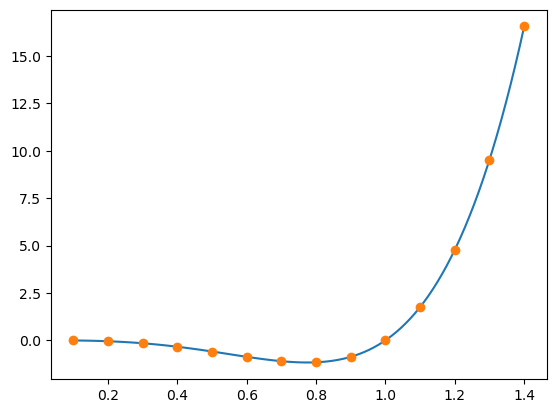

In [84]:
Rs = jnp.linspace(0.1, 1.4, 100)
analytical_grads = analytical_boundary_integral_gradient(Rs, R_reference.squeeze(), 4.0)


plt.plot(Rs, analytical_grads)
plt.plot([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4], vol_grads, 'o')